# Pjesa I · 4/4: Transformimi dhe reduktimi i dimensionit

**Qëllimi:** të përgatisim vetitë numerike për metodat që varen nga shkalla dhe shpërndarja e vlerave (korrelacioni, PCA, modelet). Së pari matim sa asimetrike janë kolonat, pastaj i transformojmë (logaritmi, rrënja katrore) dhe i shkallëzojmë (min-max, z-score). Në fund zgjedhim nënbashkësinë e vetive dhe zvogëlojmë dimensionin.

**Hyrja:** `dataset/listings_features.csv`, tabela me vetitë e reja nga notebook-u 03. Ekzekutoni së pari notebook-et 02 dhe 03.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings_features.csv").is_file() and (ROOT.parent / "dataset" / "listings_features.csv").is_file():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "dataset" / "listings_features.csv"
assert DATA_PATH.is_file(), f"Mungon {DATA_PATH.name}: ekzekutoni notebook-un 03."
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Hyrja: {DATA_PATH.name} | Rreshta: {len(df):,} | Kolona: {df.shape[1]}")

Hyrja: listings_features.csv | Rreshta: 59,846 | Kolona: 117


## 1. Asimetria para transformimit

**Asimetria** (*skewness*) tregon sa e zhvendosur është shpërndarja. Vlera pozitive do të thotë një "bisht" i gjatë djathtas: shumica e listimeve kanë vlera të vogla dhe pak listime kanë vlera shumë të mëdha (p.sh. pak host-e me qindra listime). Kjo ka rëndësi sepse:

- mesatarja dhe devijimi standard tërhiqen nga vlerat e mëdha;
- korrelacioni dhe PCA i japin peshë të tepërt atyre pak vlerave;
- standardizimi (z-score) nuk e ndreq asimetrinë, vetëm e zhvendos dhe e shkallëzon.

Rregulli i zakonshëm: |asimetria| < 0.5 është afërsisht simetrike, 0.5–1 mesatarisht asimetrike dhe > 1 shumë asimetrike.

Shqyrtojmë vetitë numerike me kuptim për analizën e çmimit. Nuk përfshijmë ID-të, koordinatat, kolonat 0/1 (binare dhe one-hot) dhe kolonat `price_quote_*`, që janë kopje të çmimit.

,asimetria,kategoria,min,mediana,mesatarja,max,bosh
price_per_person,17.93,shumë asimetrike,1.50,55.50,70.99,5000.00,0
minimum_nights,16.47,shumë asimetrike,1.00,2.00,3.73,365.00,298
host_listings_count,10.61,shumë asimetrike,0.00,4.00,68.08,5777.00,0
price,8.31,shumë asimetrike,10.00,175.00,237.16,6798.40,0
calculated_host_listings_count,7.05,shumë asimetrike,1.00,3.00,18.47,501.00,0
number_of_reviews_ltm,6.38,shumë asimetrike,0.00,3.00,8.87,789.00,0
number_of_reviews,5.49,shumë asimetrike,0.00,8.00,31.22,1705.00,0
reviews_per_month,4.69,shumë asimetrike,0.00,0.54,1.09,55.84,0
bathrooms,4.48,shumë asimetrike,0.00,1.00,1.35,30.00,0
days_since_last_review,4.04,shumë asimetrike,0.00,39.00,206.20,5289.00,12226


kategoria
shumë asimetrike          15
simetrike                  3
mesatarisht asimetrike     2


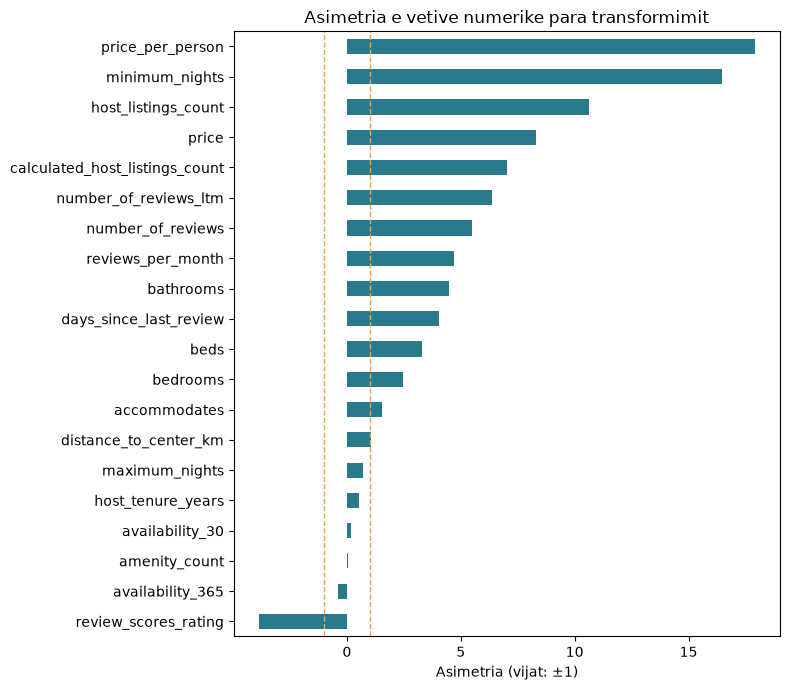

In [2]:
NUMERIC_FEATURES = [
    "price", "price_per_person", "accommodates", "bathrooms", "bedrooms", "beds", "minimum_nights", "maximum_nights",
    "availability_30", "availability_365", "number_of_reviews", "number_of_reviews_ltm", "reviews_per_month",
    "review_scores_rating", "host_listings_count", "calculated_host_listings_count", "host_tenure_years",
    "distance_to_center_km", "amenity_count", "days_since_last_review",
]
missing_columns = [col for col in NUMERIC_FEATURES if col not in df]
assert not missing_columns, f"Mungojnë kolonat: {missing_columns}"

def skew_label(value):
    if abs(value) < 0.5:
        return "simetrike"
    return "mesatarisht asimetrike" if abs(value) <= 1 else "shumë asimetrike"

skew_before = df[NUMERIC_FEATURES].skew()
skew_table = pd.DataFrame({
    "asimetria": skew_before.round(2),
    "kategoria": skew_before.map(skew_label),
    "min": df[NUMERIC_FEATURES].min(),
    "mediana": df[NUMERIC_FEATURES].median(),
    "mesatarja": df[NUMERIC_FEATURES].mean().round(2),
    "max": df[NUMERIC_FEATURES].max(),
    "bosh": df[NUMERIC_FEATURES].isna().sum(),
}).round(2).sort_values("asimetria", ascending=False)
display(skew_table)
print(skew_table["kategoria"].value_counts().to_string())

ax = skew_before.sort_values().plot.barh(figsize=(8, 7), color="#287a8c")
for limit in (-1, 1):
    ax.axvline(limit, color="#e4a64c", linestyle="--", linewidth=1)
ax.set(xlabel="Asimetria (vijat: ±1)", ylabel="", title="Asimetria e vetive numerike para transformimit")
plt.tight_layout()
plt.show()

**Përfundim.** Kolonat me asimetri pozitive mbi 1 janë kandidate për transformim në seksionin 2. Te shumica e tyre mesatarja është shumë më e madhe se mediana, shenjë e bishtit të gjatë djathtas. `review_scores_rating` ka asimetri **negative**: shumica e notave janë afër maksimumit 5. Logaritmi nuk e ndihmon këtë rast, sepse ngjesh vlerat e mëdha, ndërsa këtu bishti është majtas; prandaj kjo kolonë nuk transformohet.